# Experiment 1 - analytic continuous-categorical toy

This notebook builds the controlled microscope used to isolate practical
failure modes of the multimodal flow model:

  - **approximation difficulty** of the learned vector field
  - finite-step integration error
  - guidance instability under coupled rewards

Setup (see `dMFM_experiments/toy_categorical.py`):

$$
C_1 \sim \text{Categorical}(\pi),
\quad
Y_1 \mid C_1 = k \sim \mathcal N(\mu_k, \sigma^2 I_d),
\quad
a_1 = e_{C_1} \in \mathbb R^K
$$

with $K = 3$, $d = 2$, $\sigma = 0.15$, and three class means on a triangle of radius 0.7.

Both modalities use a Gaussian-source linear interpolant with **separate
schedules** $\alpha_y(t)$ and $\alpha_a(t)$:

$$
Y_t = (1-\alpha_y(t)) Y_0 + \alpha_y(t) Y_1, \qquad
A_t = (1-\alpha_a(t)) A_0 + \alpha_a(t) e_{C_1}.
$$

The ideal velocity is closed-form (computed by `analytic_velocity`).
This notebook focuses on Experiment 1 plus a velocity-error diagnostic;
finite-step-integration and guidance-instability experiments come next.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

REPO = Path.cwd()
EXP = REPO / "dMFM_experiments"
for p in (str(EXP), str(REPO)):
    if p not in sys.path:
        sys.path.insert(0, p)

import math
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

import toy_categorical as toy
import toy_schedules as sched_mod
from toy_schedules import (
    Schedule, baseline, discrete_ahead, continuous_ahead,
    discrete_delayed, posterior_synced, find_posterior_synced_gamma,
    posterior_curves, all_default_schedules,
)
import train_toy
from train_toy import train as train_toy_fn
from toy_velocity_diag import velocity_error_curves, relative_error

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
print("toy K, D, sigma =", toy.K, toy.D, toy.SIGMA)
print("class means:")
print(toy.get_means())

device: cpu
toy K, D, sigma = 3 2 0.15
class means:
tensor([[ 0.7000,  0.0000],
        [-0.3500,  0.6062],
        [-0.3500, -0.6062]])


## 1. Visualize the toy data

Three Gaussian modes on a triangle. Compact enough that the categorical
posterior is ambiguous in the central region.

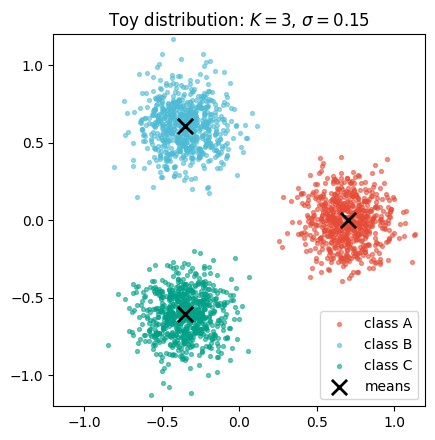

In [2]:
g = torch.Generator().manual_seed(0)
c, y = toy.sample_toy(2000, generator=g)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for k in range(toy.K):
    m = (c == k).numpy()
    ax.scatter(y[m, 0], y[m, 1], s=8, c=toy.CLASS_COLORS[k],
               alpha=0.55, label=f"class {toy.CLASS_NAMES[k]}")
mu = toy.get_means()
ax.scatter(mu[:, 0], mu[:, 1], s=120, marker="x", c="black", linewidths=2,
           label="means")
ax.set_aspect("equal")
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_title(r"Toy distribution: $K=3$, $\sigma=0.15$")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 2. Pick the posterior-synchronized schedule

Sweep $\gamma$ for $\alpha_a(t)=t^\gamma$ and pick the one whose
relative posterior entropy on $C_1$ tracks the relative posterior variance
on $Y_1$ along the joint forward process. Continuous schedule held at $\alpha_y(t)=t$.

  gamma=0.25   mismatch=0.01299
  gamma=0.5   mismatch=0.00239
  gamma=0.75   mismatch=0.00118
  gamma=1   mismatch=0.00078
  gamma=1.5   mismatch=0.00057
  gamma=2   mismatch=0.00056
  gamma=3   mismatch=0.00060
  gamma=4   mismatch=0.00062
  -> posterior-synced gamma* = 2


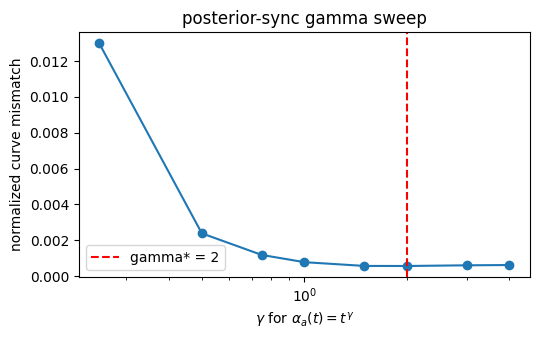

posterior-synced gamma* = 2.0


In [3]:
torch.manual_seed(0)
g_star, losses, gammas = find_posterior_synced_gamma(
    n_per_t=4096, device=DEVICE, seed=0
)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(gammas, losses, "o-")
ax.axvline(g_star, color="r", linestyle="--", label=f"gamma* = {g_star:g}")
ax.set_xscale("log")
ax.set_xlabel(r"$\gamma$ for $\alpha_a(t) = t^\gamma$")
ax.set_ylabel("normalized curve mismatch")
ax.set_title("posterior-sync gamma sweep")
ax.legend()
plt.tight_layout()
plt.show()

print(f"posterior-synced gamma* = {g_star}")

## 3. Plot the five schedules

Same color scheme used everywhere downstream.

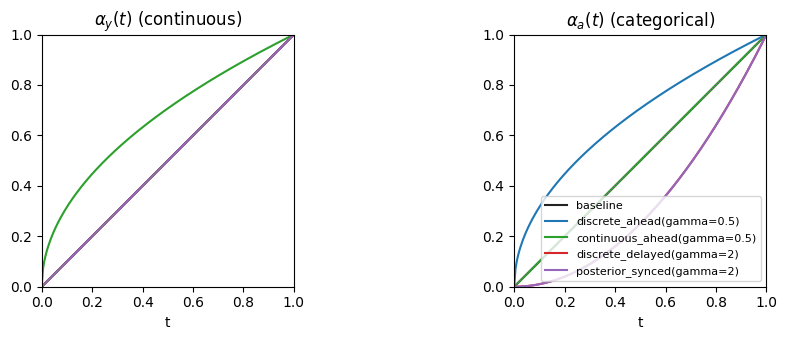

In [4]:
SCHEDULES = all_default_schedules(gamma_synced=g_star)
COLORS = ["#222222", "#1f77b4", "#2ca02c", "#d62728", "#9467bd"]
NAME2COLOR = {s.name: c for s, c in zip(SCHEDULES, COLORS)}

t = torch.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for s, c in zip(SCHEDULES, COLORS):
    axes[0].plot(t, s.alpha_y(t), color=c, label=s.name)
    axes[1].plot(t, s.alpha_a(t), color=c, label=s.name)
axes[0].plot(t, t, color="gray", linestyle=":", linewidth=0.8)
axes[1].plot(t, t, color="gray", linestyle=":", linewidth=0.8)
axes[0].set_title(r"$\alpha_y(t)$ (continuous)")
axes[1].set_title(r"$\alpha_a(t)$ (categorical)")
for ax in axes:
    ax.set_xlabel("t")
    ax.set_aspect("equal")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Sanity: posterior curves under the chosen schedule

For the posterior-synced schedule, the relative entropy on $C_1$ and the
relative variance on $Y_1$ should track each other along $t$.

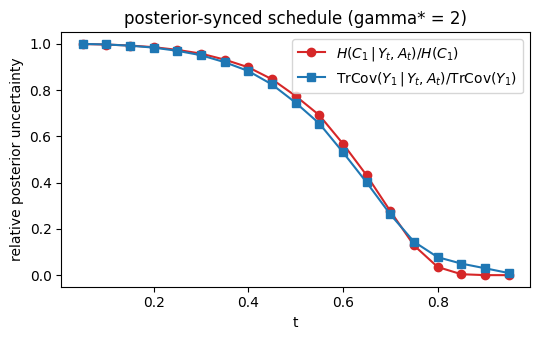

In [5]:
sched_synced = posterior_synced(g_star)
t_grid = torch.linspace(0.05, 0.95, 19, device=DEVICE)
ent, var = posterior_curves(sched_synced, t_grid, n_per_t=4096, device=DEVICE)
h0 = math.log(toy.K)
var0 = var[0].item()

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(t_grid.cpu(), (ent / h0).cpu(), "o-",
        color="#d62728", label=r"$H(C_1\,|\,Y_t,A_t)/H(C_1)$")
ax.plot(t_grid.cpu(), (var / var0).cpu(), "s-",
        color="#1f77b4", label=r"$\mathrm{TrCov}(Y_1\,|\,Y_t,A_t)/\mathrm{TrCov}(Y_1)$")
ax.set_xlabel("t")
ax.set_ylabel("relative posterior uncertainty")
ax.set_title(f"posterior-synced schedule (gamma* = {g_star:g})")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Train one MultimodalDiT per schedule

Each schedule trains the *same* network architecture (`MultimodalDiT`,
~1.85M params) on the same toy data but with different per-modality
interpolant schedules. We use 8000 steps, batch 4096 — about 4 minutes
per schedule on a single GPU.

In [ ]:
CKPT_DIR = REPO / "checkpoints" / "toy"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

STEPS = 8000
BATCH = 4096

ckpts = {}
logs = {}
for s in SCHEDULES:
    safe_name = s.name.split("(")[0]
    ckpt_path = CKPT_DIR / f"ckpt_toy_{safe_name}.pt"
    print(f"\n==== training {s.name}  ->  {ckpt_path}")
    model, ema_model, log = train_toy_fn(
        s,
        steps=STEPS, batch_size=BATCH,
        ckpt_path=str(ckpt_path), seed=0,
    )
    ckpts[s.name] = ckpt_path
    logs[s.name] = log

print("\nall checkpoints:")
for n, p in ckpts.items():
    print(f"  {n:>32s}  {p}")

## 6. Loss curves

Same total loss objective for every schedule (endpoint MSE + endpoint CE),
so loss curves are directly comparable. Schedule-induced differences in
the *input distribution* show up as differences in how easy each loss is
to drive down.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True)
for s in SCHEDULES:
    log = logs[s.name]
    c = NAME2COLOR[s.name]
    axes[0].plot(log["step"], log["loss"],   color=c, label=s.name)
    axes[1].plot(log["step"], log["loss_y"], color=c)
    axes[2].plot(log["step"], log["loss_c"], color=c)
axes[0].set_title("total loss (L_y + L_c)")
axes[1].set_title("L_y  (continuous endpoint MSE)")
axes[2].set_title("L_c  (categorical endpoint CE)")
for ax in axes:
    ax.set_xlabel("step")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

## 7. Velocity-error diagnostic (failure mode 1: approximation)

For each trained model, sample $(y_t, a_t)$ from its own training-time
forward process at a grid of $t$, then compare the network velocity

$$
\hat b^y_t = \frac{\dot\alpha_y}{1-\alpha_y}\,(\hat y_1 - y_t),
\quad
\hat b^a_t = \frac{\dot\alpha_a}{1-\alpha_a}\,(\mathrm{softmax}(\hat z) - a_t)
$$

against the analytic ideal. Errors here are pure approximation error -
no integration, no guidance.

In [ ]:
diag = {}
t_grid = torch.linspace(0.05, 0.95, 19)
for s in SCHEDULES:
    print(f"diag {s.name} ...")
    diag[s.name] = velocity_error_curves(
        str(ckpts[s.name]), s, t_grid=t_grid,
        n_per_t=8192, device=DEVICE, use_ema=True, seed=42,
    )
print("done.")

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)

for s in SCHEDULES:
    d = diag[s.name]
    rel = relative_error(d)
    c = NAME2COLOR[s.name]
    axes[0, 0].plot(d["t_grid"], d["mse_y"], color=c, label=s.name)
    axes[0, 1].plot(d["t_grid"], d["mse_a"], color=c)
    axes[1, 0].plot(d["t_grid"], rel["rel_y"], color=c)
    axes[1, 1].plot(d["t_grid"], rel["rel_a"], color=c)

axes[0, 0].set_title(r"$\mathbb E\,\|\hat b^y - b^y\|^2$")
axes[0, 1].set_title(r"$\mathbb E\,\|\hat b^a - b^a\|^2$")
axes[1, 0].set_title(r"relative: $\|\hat b^y-b^y\|^2/\|b^y\|^2$")
axes[1, 1].set_title(r"relative: $\|\hat b^a-b^a\|^2/\|b^a\|^2$")
for ax in axes.flat:
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("t")
axes[0, 0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

## 8. Notes / next steps

- The velocity-error diagnostic depends on a $\dot\alpha/(1-\alpha)$ factor
  that diverges at $t \to 1$ for both schedules, so MSE blows up there
  even when the *endpoint* prediction is accurate. The relative metric is
  more informative for cross-schedule comparisons.
- Posterior-synced schedule: gamma_star = $g_*$. The fact that the
  optimum sits modestly above 1 (mild discrete-delay) is a function of
  $\sigma$ and $K$ - the categorical posterior collapses faster than
  the continuous variance for our $\sigma=0.15$ regime, so syncing requires
  slowing $\alpha_a$ down.
- Next experiments: (i) finite-step integration error, sweeping step count
  for both Euler and RK4 with both the analytic and learned velocity;
  (ii) guidance instability under a coupled reward such as
  $r(y, c) = -\|y - \mu_{k^\star}\|^2 + \lambda\,\log p(C_1=k^\star\,|\,y_t,a_t)$.